# Experiment 002–005 · 证据保留可视化

## tl;dr

本 notebook 用两个**预先按“问题简单、证据可由人直接定位、覆盖文本/视觉两类”标准选择**的 test case，比较 50% retention 下五种证据选择：

1. **Human-identified evidence**：人工定位的参考证据，不把它宣称为唯一 ground truth；
2. **Raw Qwen**：实验 002 的原始 Qwen 相似度方案（使用实验 003 中按同一 test split 重跑并保存的结果）；
3. **Aligned encoder**：实验 003 的 calibrated 图文对齐分数；
4. **Utility v1**：实验 004 的 learned utility scorer；
5. **Utility v2**：实验 005 的两阶段 conditional utility scorer（prefilter fraction = 0.25）。

核心观察分成两层：

- `sample 13` 是文本主导题：问题与答案都很短，可直接检查各方法是否保留“green eggs → emu”的当前上下文。
- `sample 147` 是视觉主导题：可检查“挥手区域是否被保留”，并对照自动指标与人工语义判断是否一致。

> 这是**定性 case study**，用于解释机制和生成后续假设，不代表总体效果，也不能替代 50 个 test 样本上的汇总指标。

## Context & Methods

### 比较口径

- Split：Experiment 004/005 固定 test split（50 个样本）。
- Retention：统一为 `0.50`；seed：统一为 `0`；Utility v2 的 prefilter fraction 为 `0.25`。
- 文本和视觉选择都映射回**原始 Qwen candidate token 索引**后比较，因此不同 scorer 的输出位于同一坐标系。
- 每个方法的 score 只在方法内部作 percentile normalization；不同 scorer 的原始数值尺度不同，不能直接比较绝对值。
- 图中“保留/删除”来自正式实验保存的 `selected_*_indices`，不是重新运行 scorer 得到的近似结果。

### Key Assumptions

- 人工证据是“一个人完成该题至少会查看的区域/语句”，不是唯一正确的证据集合。
- `sample 147` 的“挥手”需要看到手臂/手掌区域；人工框只标出最直接区域，但全身姿态也可能提供辅助信息。
- 最终生成正确性同时受证据选择、保留后的上下文组织和生成模型能力影响；因此“答错”不等价于“关键证据一定被删掉”。

### 文件变更说明

本分析只新建 `projects/mllm_prune/notebooks/viz.ipynb`。没有新建或修改其他项目代码/数据文件；人工标注和 case 配置直接保存在下面的参数单元格中，避免产生隐式派生数据。

In [1]:
from __future__ import annotations

import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image
import torch
from transformers import AutoConfig, AutoProcessor, AutoTokenizer
from qwen_vl_utils import process_vision_info
from IPython.display import HTML, Markdown, display


def find_project_root() -> Path:
    candidates = [Path.cwd(), *Path.cwd().parents, Path('/data2/wenhaozhang/projects/mllm_prune')]
    for candidate in candidates:
        if (candidate / 'src/mllm_prune').is_dir() and (candidate / 'AGENTS.md').is_file():
            return candidate.resolve()
    raise FileNotFoundError('Cannot locate the mllm_prune project root')


PROJECT_ROOT = find_project_root()
WORKSPACE_ROOT = PROJECT_ROOT.parents[1]
RUN_ROOT = WORKSPACE_ROOT / 'runs/mllm_prune'
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from mllm_prune.config import path_from_env
from mllm_prune.data.mmcoqa import build_prompt_spec, resolve_sample
from mllm_prune.models.qwen25vl import _expand_image_pads, _make_text_chunks, _token_groups

IMAGE_DIR = path_from_env('MMCOQA_IMAGE_DIR')
QWEN_PATH = path_from_env('QWEN_MODEL_PATH')
TEST_SPLIT = PROJECT_ROOT / 'data/interim/experiment_004/splits/test.json'

assert IMAGE_DIR and IMAGE_DIR.is_dir(), IMAGE_DIR
assert QWEN_PATH and QWEN_PATH.is_dir(), QWEN_PATH
assert TEST_SPLIT.is_file(), TEST_SPLIT

RETENTION = 0.50
SEED = 0
CASE_CONFIG = {
    13: {
        'role': 'text-dominant',
        'human_evidence_terms': [
            'very large, thick-shelled, green eggs',
            'demonstrated in the emu',
        ],
    },
    147: {
        'role': 'vision-dominant',
        'evidence_image_index': 6,  # zero-based: {image#7} -> 447.jpg
        'human_roi_xyxy': (0.04, 0.00, 0.42, 0.30),
        'human_note': 'Raised arm and open hand: the person is waving.',
    },
}

METHOD_SPECS = [
    {'label': 'Raw Qwen', 'experiment': '003', 'method': 'raw_qwen_joint'},
    {'label': 'Aligned encoder', 'experiment': '003', 'method': 'aligned_calibrated'},
    {'label': 'Utility v1', 'experiment': '004', 'method': 'learned_utility_joint'},
    {'label': 'Utility v2', 'experiment': '005', 'method': 'conditional_utility_joint', 'prefilter_fraction': 0.25},
]

# Manual semantic reading is deliberately kept separate from the experiment's
# automatic exact/robust string metric. It is only used for these two cases.
MANUAL_SEMANTIC = {
    13: {'Raw Qwen': True, 'Aligned encoder': False, 'Utility v1': True, 'Utility v2': True},
    147: {'Raw Qwen': False, 'Aligned encoder': False, 'Utility v1': True, 'Utility v2': True},
}

COLORS = {'keep': '#2F6B8A', 'delete': '#D9DEE3', 'evidence': '#D28E00', 'text': '#222222'}
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.titlesize': 11})

print(f'Project: {PROJECT_ROOT}')
print(f'Source split: {TEST_SPLIT.relative_to(PROJECT_ROOT)}')
print(f'Cases: {list(CASE_CONFIG)}; retention={RETENTION}; seed={SEED}')

/data2/wenhaozhang/envs/mllm_prune/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: /data2/wenhaozhang/projects/mllm_prune
Source split: data/interim/experiment_004/splits/test.json
Cases: [13, 147]; retention=0.5; seed=0


## Data

### 1. 读取正式实验结果并锁定比较行

来源均为已有正式 run，不重新训练或推理：

- `runs/mllm_prune/experiment_003/predictions/shard_*.jsonl`
- `runs/mllm_prune/experiment_004/results.jsonl`
- `runs/mllm_prune/experiment_005/predictions/shard_*.jsonl`
- `data/interim/experiment_004/splits/test.json`


In [2]:
def read_jsonl(paths):
    rows = []
    for path in paths:
        with Path(path).open(encoding='utf-8') as handle:
            rows.extend(json.loads(line) for line in handle if line.strip())
    return rows


experiment_rows = {
    '003': read_jsonl(sorted((RUN_ROOT / 'experiment_003/predictions').glob('shard_*.jsonl'))),
    '004': read_jsonl([RUN_ROOT / 'experiment_004/results.jsonl']),
    '005': read_jsonl(sorted((RUN_ROOT / 'experiment_005/predictions').glob('shard_*.jsonl'))),
}
with TEST_SPLIT.open(encoding='utf-8') as handle:
    subset = json.load(handle)
samples = {int(row['sample_id']): row for row in subset['data']}


def select_result(spec, sample_id):
    matches = []
    for row in experiment_rows[spec['experiment']]:
        if (
            int(row['sample_id']) == sample_id
            and row['method'] == spec['method']
            and float(row['retention']) == RETENTION
            and int(row.get('seed', 0)) == SEED
        ):
            expected_prefilter = spec.get('prefilter_fraction')
            if expected_prefilter is None or float(row.get('prefilter_fraction', 0.0)) == expected_prefilter:
                matches.append(row)
    if len(matches) != 1:
        raise ValueError(f'Expected one result for {spec} sample={sample_id}, got {len(matches)}')
    return matches[0]


results = {
    sample_id: {spec['label']: select_result(spec, sample_id) for spec in METHOD_SPECS}
    for sample_id in CASE_CONFIG
}

summary_rows = []
for sample_id, by_method in results.items():
    for label, row in by_method.items():
        plan = row['plan']
        summary_rows.append({
            'sample': sample_id,
            'role': CASE_CONFIG[sample_id]['role'],
            'method': label,
            'text kept': f"{len(plan['selected_text_indices'])}/{len(plan['text_token_scores'])}",
            'vision kept': f"{len(plan['selected_vision_indices'])}/{len(plan['vision_token_scores'])}",
            'actual retention': row['actual_candidate_retention'],
            'prediction': row['prediction'],
            'gold': row['answer'],
            'metric correct': bool(row['correct_robust']),
            'manual semantic': MANUAL_SEMANTIC[sample_id][label],
        })

summary = pd.DataFrame(summary_rows)
display(summary.style.format({'actual retention': '{:.3f}'}).map(
    lambda value: 'background-color: #DCEFE3' if value is True else ('background-color: #F5D9D6' if value is False else ''),
    subset=['metric correct', 'manual semantic'],
))

,sample,role,method,text kept,vision kept,actual retention,prediction,gold,metric correct,manual semantic
0,13,text-dominant,Raw Qwen,584/766,65/532,0.500,emu,emu,True,True
1,13,text-dominant,Aligned encoder,212/766,437/532,0.500,The large bird that lays big green eggs is the American alligator.,emu,False,False
2,13,text-dominant,Utility v1,649/766,0/532,0.500,emu.,emu,True,True
3,13,text-dominant,Utility v2,617/766,32/532,0.500,emu.,emu,True,True
4,147,vision-dominant,Raw Qwen,227/227,1567/3362,0.500,The image shows a man wearing a racing suit with the number 11 on it. It is not possible to determine what he did to his arm from the,waving,False,False
5,147,vision-dominant,Aligned encoder,227/227,1567/3362,0.500,"The image shows a man wearing a racing suit and sunglasses, but it does not provide any information about him doing anything to his arm. Therefore, it is not",waving,False,False
6,147,vision-dominant,Utility v1,206/227,1588/3362,0.500,He waved his arm.,waving,False,True
7,147,vision-dominant,Utility v2,206/227,1588/3362,0.500,He waved his arm.,waving,False,True


### 2. 重建共同的 Qwen token/chunk 坐标

这里只加载本地 processor 和 config，在 CPU 上重建 tokenizer offset、视觉网格与 chunk 布局；**不加载 7B 模型、不重新打分**。该步骤用于把保存的 token index 映射回可读文本和图片 patch。

In [3]:
# Formal experiments used the checkpoint's slow image processor plus a fast
# tokenizer (needed for offset mapping). Newer Transformers defaults otherwise
# change the visual grid, so pin the two components separately.
MIN_PIXELS = 256 * 28 * 28
MAX_PIXELS = 401408  # configs/experiments/005_learned_utility_scorer_v2.yaml
processor = AutoProcessor.from_pretrained(
    QWEN_PATH, local_files_only=True, use_fast=False,
    min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS,
)
processor.tokenizer = AutoTokenizer.from_pretrained(QWEN_PATH, local_files_only=True, use_fast=True)
qwen_config = AutoConfig.from_pretrained(QWEN_PATH, local_files_only=True)
merge_size = int(qwen_config.vision_config.spatial_merge_size)


def reconstruct_case(sample_id: int) -> dict:
    sample = samples[sample_id]
    instruction, context, image_paths = resolve_sample(subset, sample, IMAGE_DIR)
    prompt_spec = build_prompt_spec(instruction, context, image_paths)
    prompt = processor.apply_chat_template(prompt_spec.messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(prompt_spec.messages)
    assert not video_inputs
    encoded = processor(text=[prompt], images=image_inputs, videos=None, padding=True, return_tensors='pt')
    grids = encoded['image_grid_thw']
    image_counts = (grids.prod(-1) // merge_size**2).tolist()
    expanded = _expand_image_pads(prompt, image_counts)
    text_positions, query_positions, source_ids, offsets = _token_groups(
        expanded, processor.tokenizer, prompt_spec.candidate_fragments,
        prompt_spec.query_text, encoded['input_ids'][0],
    )
    text_positions = sorted(text_positions)
    chunks = _make_text_chunks(
        text_positions, source_ids, offsets, expanded,
        min_tokens=16, max_tokens=64,
    )
    token_texts = [expanded[offsets[pos][0]:offsets[pos][1]] for pos in text_positions]
    chunk_texts = [''.join(token_texts[i] for i in chunk.token_indices).strip() for chunk in chunks]
    image_shapes = [(int(g[1]) // merge_size, int(g[2]) // merge_size) for g in grids]
    return {
        'sample': sample,
        'context': context,
        'question': prompt_spec.query_text.replace('Question:', '').replace('Answer:', '').strip(),
        'answer': sample['response'],
        'image_paths': image_paths,
        'image_shapes': image_shapes,
        'image_counts': [int(x) for x in image_counts],
        'token_texts': token_texts,
        'chunks': chunks,
        'chunk_texts': chunk_texts,
    }


case_data = {sample_id: reconstruct_case(sample_id) for sample_id in CASE_CONFIG}
for sample_id, data in case_data.items():
    method_plan = next(iter(results[sample_id].values()))['plan']
    assert len(data['token_texts']) == len(method_plan['text_token_scores'])
    assert sum(data['image_counts']) == len(method_plan['vision_token_scores'])
    print(
        f"sample={sample_id}: text={len(data['token_texts'])}, "
        f"vision={sum(data['image_counts'])}, images={len(data['image_paths'])}, "
        f"question={data['question']!r}"
    )

sample=13: text=766, vision=532, images=2, question='which large bird of the country lays big green eggs'
sample=147: text=227, vision=3362, images=7, question='What did he do to his arm？'


## Results

## Case A — sample 13：文本主导证据

问题问“哪种大型鸟会产很大的绿色蛋？”当前文本明确描述绿色蛋，并在后文给出 `emu`。下面先定位人工证据所在 chunk，再比较四种方法是否完整保留它们。

可视化编码：

- 每个横条是一段 text chunk；横向位置表示原文顺序。
- 深蓝表示该 chunk 中被保留 token 的比例，浅灰表示删除比例。
- 金色边框和 `★` 表示该 chunk 命中人工证据短语。
- 这张图显示的是**保留行为**；表格另外显示 scorer 排名和最终答案。

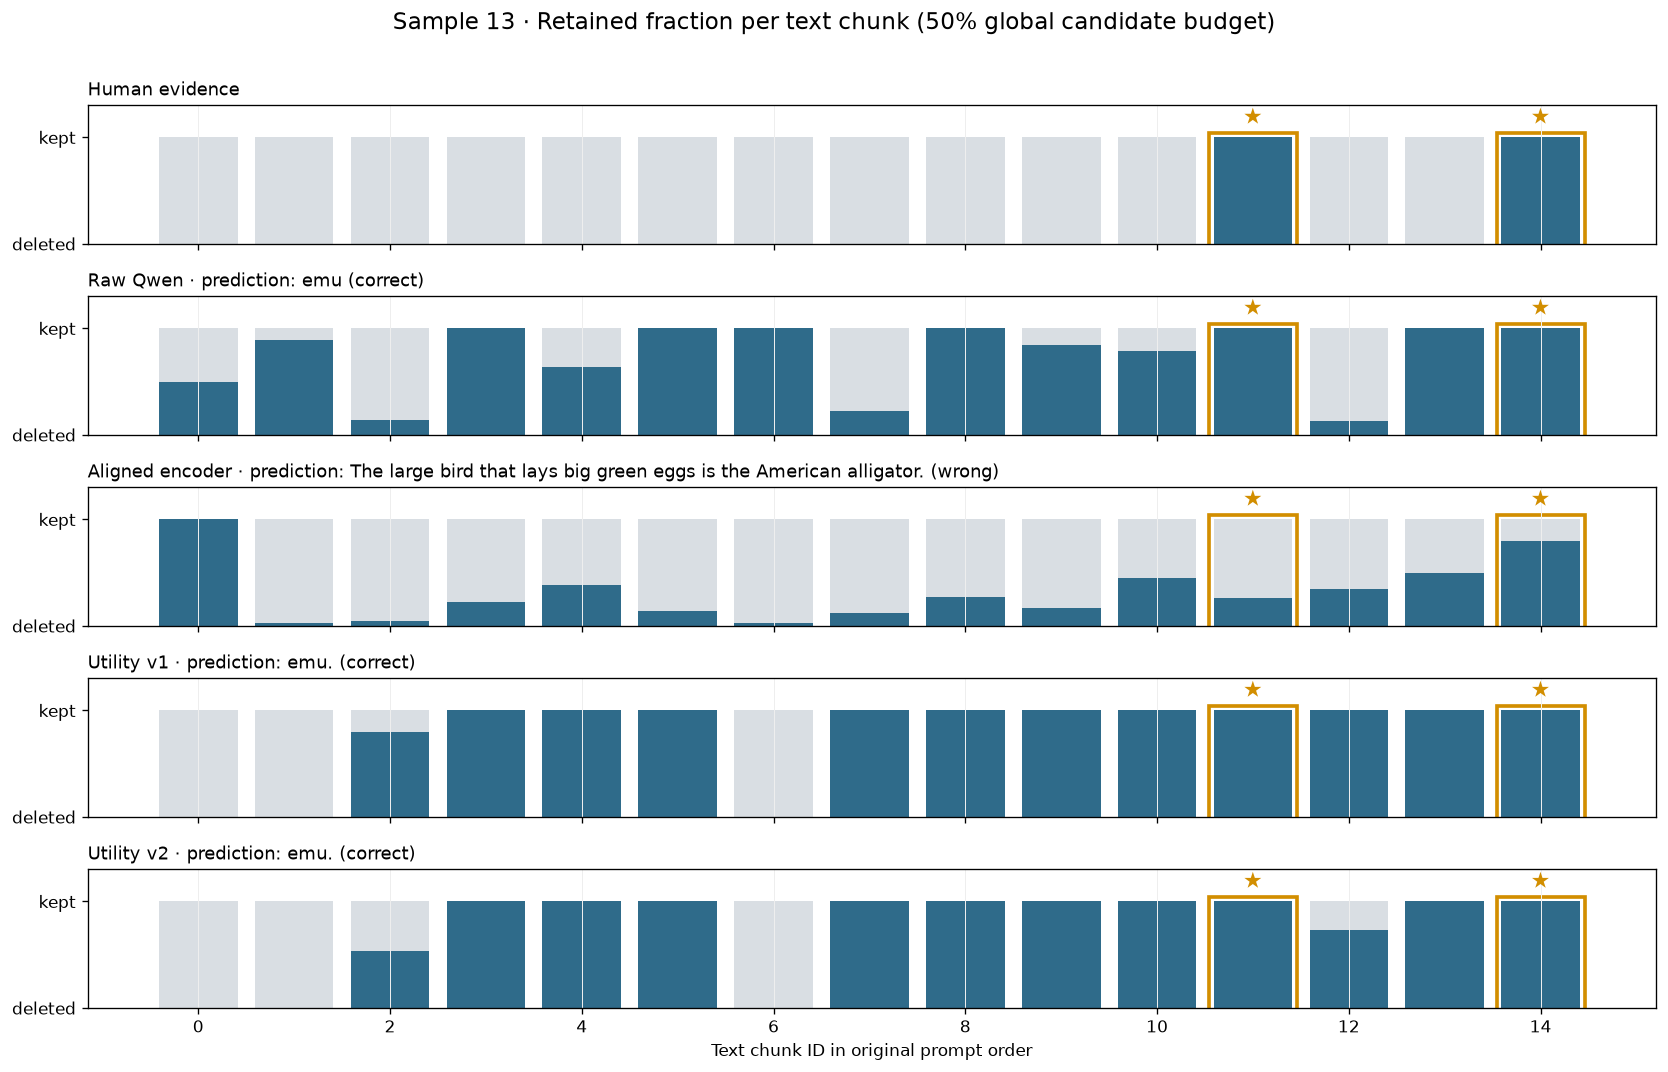

Human-identified evidence chunks:
  chunk 11: The pair mate every day or two, and every second or third day the female lays one of a clutch of five to fifteen very large, thick-shelled, green eggs. The shell is around 1 mm (0.04 in) thick, but rather thinner in northern regions according to indigenous Australians.
  chunk 14: The first verified occurrence of genetically identical avian twins was demonstrated in the emu. The egg surface is granulated and pale green. During the incubation period, the egg turns dark green, although if the egg never hatches, it will turn white from the bleaching effect of the sun.


In [4]:
def evidence_chunk_ids(sample_id: int) -> set[int]:
    terms = [term.lower() for term in CASE_CONFIG[sample_id]['human_evidence_terms']]
    return {
        index for index, text in enumerate(case_data[sample_id]['chunk_texts'])
        if any(term in text.lower() for term in terms)
    }


def chunk_metrics(sample_id: int, method_label: str):
    data = case_data[sample_id]
    plan = results[sample_id][method_label]['plan']
    selected = set(plan['selected_text_indices'])
    token_scores = np.asarray(plan['text_token_scores'], dtype=float)
    rows = []
    for index, (chunk, text) in enumerate(zip(data['chunks'], data['chunk_texts'])):
        ids = list(chunk.token_indices)
        rows.append({
            'chunk': index,
            'kept_fraction': np.mean([i in selected for i in ids]),
            'score': float(np.mean(token_scores[ids])),
            'tokens': len(ids),
            'text': ' '.join(text.split()),
        })
    return pd.DataFrame(rows)


sample_id = 13
evidence_ids = evidence_chunk_ids(sample_id)
assert evidence_ids, 'Human evidence terms did not align to any chunk'
panel_labels = ['Human evidence', *[spec['label'] for spec in METHOD_SPECS]]
fig, axes = plt.subplots(len(panel_labels), 1, figsize=(14, 8.8), sharex=True)

for axis, label in zip(axes, panel_labels):
    if label == 'Human evidence':
        kept = np.array([1.0 if i in evidence_ids else 0.0 for i in range(len(case_data[sample_id]['chunks']))])
    else:
        kept = chunk_metrics(sample_id, label)['kept_fraction'].to_numpy()
    y = np.zeros_like(kept)
    axis.bar(np.arange(len(kept)), kept, color=COLORS['keep'], width=0.82, label='retained')
    axis.bar(np.arange(len(kept)), 1 - kept, bottom=kept, color=COLORS['delete'], width=0.82, label='deleted')
    for evidence_id in evidence_ids:
        axis.add_patch(Rectangle((evidence_id - 0.46, -0.04), 0.92, 1.08, fill=False,
                                 edgecolor=COLORS['evidence'], linewidth=2.2))
        axis.text(evidence_id, 1.08, '★', ha='center', va='bottom', color=COLORS['evidence'], fontsize=13)
    suffix = ''
    if label != 'Human evidence':
        row = results[sample_id][label]
        suffix = f" · prediction: {row['prediction']} ({'correct' if row['correct_robust'] else 'wrong'})"
    axis.set_title(label + suffix, loc='left')
    axis.set_ylim(0, 1.30)
    axis.set_yticks([0, 1], ['deleted', 'kept'])
    axis.grid(axis='x', color='#EEEEEE', linewidth=0.6)

axes[-1].set_xlabel('Text chunk ID in original prompt order')
fig.suptitle('Sample 13 · Retained fraction per text chunk (50% global candidate budget)', y=1.01, fontsize=14)
fig.tight_layout()
plt.show()

print('Human-identified evidence chunks:')
for chunk_id in sorted(evidence_ids):
    print(f'  chunk {chunk_id}: {case_data[sample_id]["chunk_texts"][chunk_id]}')

In [5]:
sample_id = 13
audit_rows = []
for label in [spec['label'] for spec in METHOD_SPECS]:
    frame = chunk_metrics(sample_id, label)
    score_rank = frame['score'].rank(method='min', ascending=False).astype(int)
    for evidence_id in sorted(evidence_ids):
        row = frame.loc[evidence_id]
        audit_rows.append({
            'method': label,
            'evidence chunk': evidence_id,
            'tokens': int(row['tokens']),
            'kept fraction': row['kept_fraction'],
            'mean token score': row['score'],
            'score rank / chunks': f"{score_rank.loc[evidence_id]}/{len(frame)}",
            'prediction': results[sample_id][label]['prediction'],
            'metric correct': results[sample_id][label]['correct_robust'],
            'manual semantic': MANUAL_SEMANTIC[sample_id][label],
        })

text_audit = pd.DataFrame(audit_rows)
display(text_audit.style.format({'kept fraction': '{:.1%}', 'mean token score': '{:.4f}'}))

,method,evidence chunk,tokens,kept fraction,mean token score,score rank / chunks,prediction,metric correct,manual semantic
0,Raw Qwen,11,64,100.0%,0.2587,5/15,emu,True,True
1,Raw Qwen,14,60,100.0%,0.3028,1/15,emu,True,True
2,Aligned encoder,11,64,26.6%,0.6539,7/15,The large bird that lays big green eggs is the American alligator.,False,False
3,Aligned encoder,14,60,80.0%,0.7629,3/15,The large bird that lays big green eggs is the American alligator.,False,False
4,Utility v1,11,64,100.0%,0.2587,5/15,emu.,True,True
5,Utility v1,14,60,100.0%,0.3028,1/15,emu.,True,True
6,Utility v2,11,64,100.0%,0.6539,7/15,emu.,True,True
7,Utility v2,14,60,100.0%,0.7629,3/15,emu.,True,True


**如何读 Case A：** 若某方法答错且关键 chunk 的保留率/排名也低，case 支持“关键文本没有被 scorer 稳定识别”的解释；若关键 chunk 已完整保留但仍答错，则要继续检查生成、上下文干扰或答案规范化，而不能把错误全部归因于 pruning。

## Case B — sample 147：视觉主导证据

当前问题是 “What did he do to his arm?”，唯一直接证据位于最后一张图片 `447.jpg`：人物抬起手臂并张开手掌，语义是 **waving**。

五列图统一映射到 Qwen projector 后的视觉 token 网格：

- **Human evidence**：金色框标出人工查看的直接证据区域；
- 四种方法：被删除的 patch 加深灰色遮罩，保留 patch 保持可见；蓝色边界辅助辨认网格，避免只靠颜色区分；
- 标题给出人工 ROI 内 token 的保留率和该方法最终预测。

注意：ROI retention 衡量“关键区域有没有留下”，不是对答案正确性的替代指标。

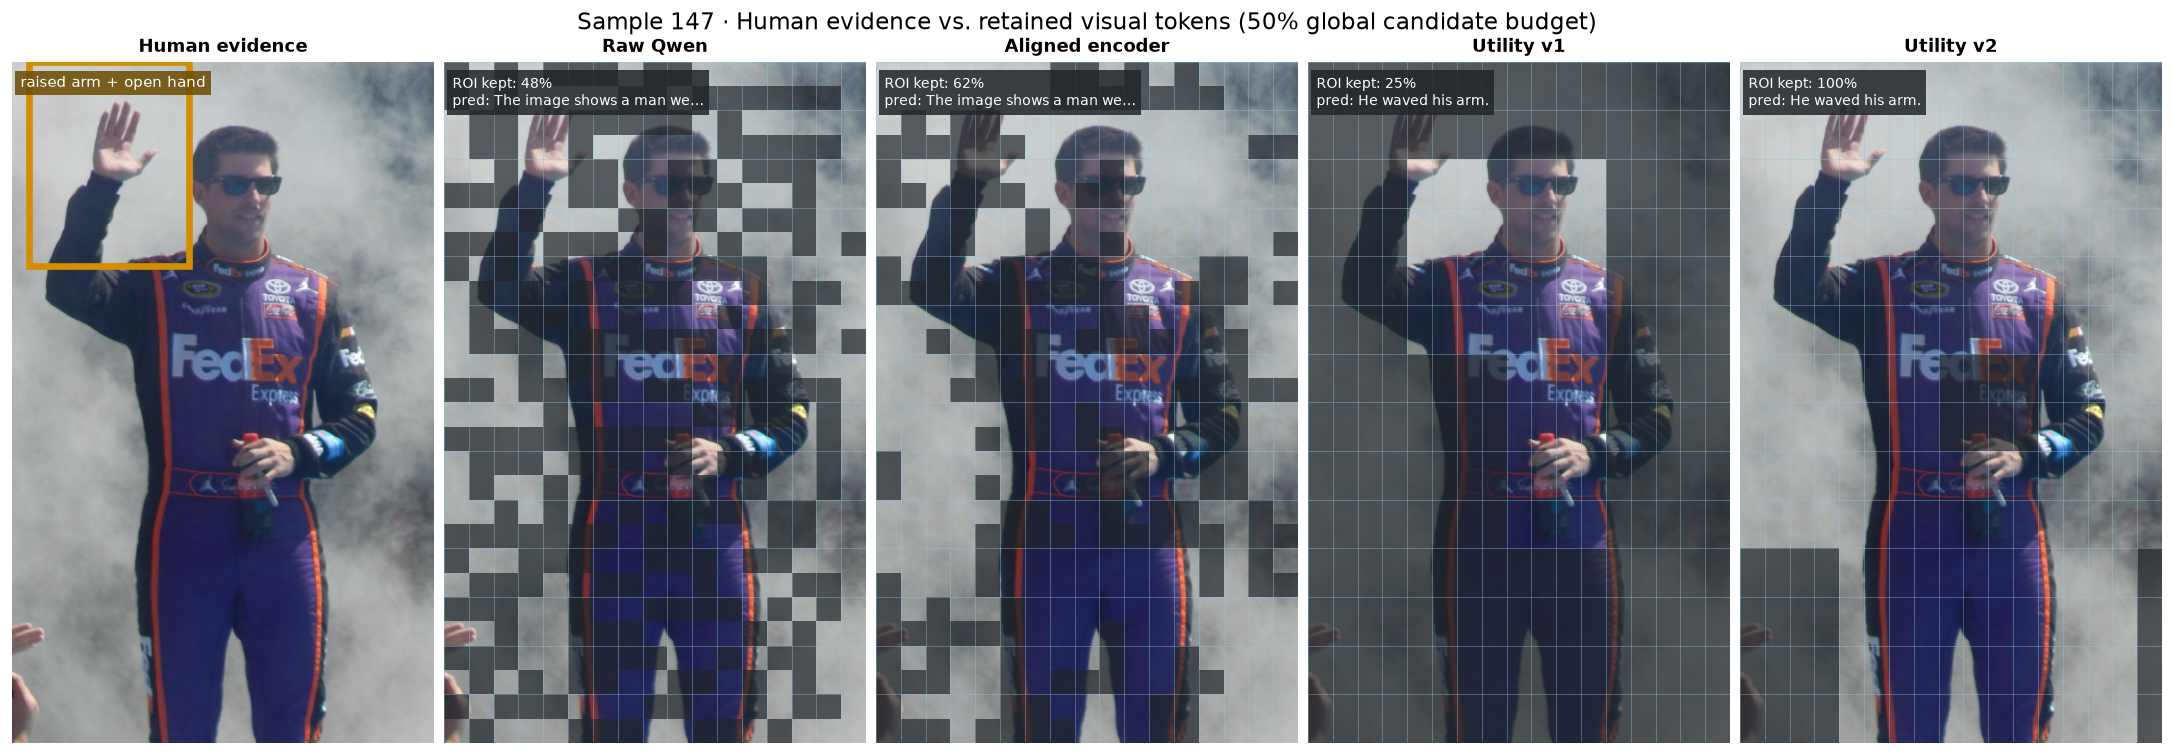

In [6]:
def image_token_slice(image_counts, image_index):
    start = int(sum(image_counts[:image_index]))
    return slice(start, start + int(image_counts[image_index]))


def roi_token_mask(height, width, roi_xyxy):
    x0, y0, x1, y1 = roi_xyxy
    yy, xx = np.mgrid[0:height, 0:width]
    centers_x = (xx + 0.5) / width
    centers_y = (yy + 0.5) / height
    return (centers_x >= x0) & (centers_x <= x1) & (centers_y >= y0) & (centers_y <= y1)


sample_id = 147
data = case_data[sample_id]
image_index = CASE_CONFIG[sample_id]['evidence_image_index']
image = Image.open(data['image_paths'][image_index]).convert('RGB')
grid_h, grid_w = data['image_shapes'][image_index]
token_slice = image_token_slice(data['image_counts'], image_index)
roi = CASE_CONFIG[sample_id]['human_roi_xyxy']
roi_mask = roi_token_mask(grid_h, grid_w, roi)

fig, axes = plt.subplots(1, 5, figsize=(18, 6.2), sharex=True, sharey=True, constrained_layout=True)
fig.suptitle('Sample 147 · Human evidence vs. retained visual tokens (50% global candidate budget)', fontsize=14)

for axis, label in zip(axes, panel_labels):
    axis.imshow(image)
    axis.set_title(label, fontweight='bold')
    axis.axis('off')
    if label == 'Human evidence':
        x0, y0, x1, y1 = roi
        axis.add_patch(Rectangle((x0 * image.width, y0 * image.height),
                                 (x1 - x0) * image.width, (y1 - y0) * image.height,
                                 fill=False, edgecolor=COLORS['evidence'], linewidth=4))
        axis.text(0.02, 0.98, 'raised arm + open hand', transform=axis.transAxes,
                  ha='left', va='top', color='white', fontsize=9,
                  bbox={'facecolor': '#6B4B00', 'alpha': 0.85, 'pad': 3, 'edgecolor': 'none'})
        continue

    plan = results[sample_id][label]['plan']
    selected = set(plan['selected_vision_indices'])
    local_ids = np.arange(token_slice.start, token_slice.stop)
    keep = np.array([index in selected for index in local_ids], dtype=bool).reshape(grid_h, grid_w)
    delete_overlay = np.where(keep, np.nan, 1.0)
    axis.imshow(delete_overlay, extent=(0, image.width, image.height, 0),
                cmap=LinearSegmentedColormap.from_list('deleted', [(0, '#20252A'), (1, '#20252A')]),
                alpha=0.68, interpolation='nearest', vmin=0, vmax=1)
    # Sparse grid lines make patch boundaries legible without dominating the image.
    for x in np.linspace(0, image.width, grid_w + 1)[::max(1, grid_w // 10)]:
        axis.axvline(x, color='#8EC7E6', linewidth=0.35, alpha=0.65)
    for y in np.linspace(0, image.height, grid_h + 1)[::max(1, grid_h // 10)]:
        axis.axhline(y, color='#8EC7E6', linewidth=0.35, alpha=0.65)
    roi_retention = float(keep[roi_mask].mean())
    row = results[sample_id][label]
    prediction_short = row['prediction'][:24] + ('…' if len(row['prediction']) > 24 else '')
    axis.text(0.02, 0.98,
              f"ROI kept: {roi_retention:.0%}\npred: {prediction_short}",
              transform=axis.transAxes, ha='left', va='top', color='white', fontsize=8.5,
              bbox={'facecolor': '#20252A', 'alpha': 0.85, 'pad': 3, 'edgecolor': 'none'})

plt.show()

In [7]:
sample_id = 147
data = case_data[sample_id]
image_index = CASE_CONFIG[sample_id]['evidence_image_index']
grid_h, grid_w = data['image_shapes'][image_index]
token_slice = image_token_slice(data['image_counts'], image_index)
roi_mask = roi_token_mask(grid_h, grid_w, CASE_CONFIG[sample_id]['human_roi_xyxy'])
visual_rows = []

for label in [spec['label'] for spec in METHOD_SPECS]:
    row = results[sample_id][label]
    plan = row['plan']
    selected = set(plan['selected_vision_indices'])
    local_ids = np.arange(token_slice.start, token_slice.stop)
    keep = np.array([index in selected for index in local_ids], dtype=bool).reshape(grid_h, grid_w)
    score_grid = np.asarray(plan['vision_token_scores'][token_slice], dtype=float).reshape(grid_h, grid_w)
    visual_rows.append({
        'method': label,
        'evidence image kept': keep.mean(),
        'human ROI kept': keep[roi_mask].mean(),
        'ROI mean score': score_grid[roi_mask].mean(),
        'whole-image mean score': score_grid.mean(),
        'prediction': row['prediction'],
        'gold': row['answer'],
        'metric correct': row['correct_robust'],
        'manual semantic': MANUAL_SEMANTIC[sample_id][label],
    })

visual_audit = pd.DataFrame(visual_rows)
display(visual_audit.style.format({
    'evidence image kept': '{:.1%}', 'human ROI kept': '{:.1%}',
    'ROI mean score': '{:.4f}', 'whole-image mean score': '{:.4f}',
}))

,method,evidence image kept,human ROI kept,ROI mean score,whole-image mean score,prediction,gold,metric correct,manual semantic
0,Raw Qwen,49.6%,47.9%,0.0314,0.0291,The image shows a man wearing a racing suit with the number 11 on it. It is not possible to determine what he did to his arm from the,waving,False,False
1,Aligned encoder,63.9%,62.5%,0.6005,0.6337,"The image shows a man wearing a racing suit and sunglasses, but it does not provide any information about him doing anything to his arm. Therefore, it is not",waving,False,False
2,Utility v1,20.2%,25.0%,0.0314,0.0291,He waved his arm.,waving,False,True
3,Utility v2,88.2%,100.0%,0.6005,0.6337,He waved his arm.,waving,False,True


### 结果边界

这两个 case 有意覆盖两类诊断，而不是用于“证明某个方案最好”：

1. **Case A** 检查文本证据 chunk 的识别与保留；它能把最终答对/答错与关键 chunk 的保留率对齐。
2. **Case B** 检查视觉证据 ROI，并将自动字符串指标与人工语义判断分开，避免把同义表述误当成模型失败。
3. score 的绝对值不能跨方法比较；可比较的是同一方法内排序、是否越过预算阈值，以及最终的 binary retained mask。
4. 人工 ROI / 关键词由研究者根据题意标注，存在主观性；未来若扩展到定量研究，应由多人独立标注并报告一致性。

## Takeaways

- 这套可视化把“scorer 打分 → 预算选择 → 关键证据是否保留 → 最终生成答案”放在同一条链上，避免仅凭 accuracy 猜测失败位置。
- `sample 13` 中，Raw Qwen、Utility v1、Utility v2 都完整保留两个关键文本 chunk 并回答 `emu`；Aligned 只保留 green-eggs chunk 的 26.6% 和 emu chunk 的 80.0%，回答成 `American alligator`。这个 case 支持“跨模态预算分配过度偏向视觉，破坏文本证据”的局部解释。
- `sample 147` 中，human ROI 保留率依次为 Raw 47.9%、Aligned 62.5%、Utility v1 25.0%、Utility v2 100.0%。然而 Utility v1/v2 都输出 `He waved his arm.`，语义上正确，却都被自动字符串指标判错；因此当前报告中的 accuracy 至少存在可见的 false negative。
- 同一个视觉 case 还说明 ROI retention 不是充分条件：Aligned 保留 62.5% 的手臂/手掌 ROI 仍未识别动作，而 Utility v1 只保留 25% 却能生成正确语义。证据选择、模型视觉理解和评测规范化必须分层诊断。
- 下一步最有价值的扩展不是继续手挑更多漂亮案例，而是把 ROI/chunk overlap 指标批量化：在一小批人工标注样本上统计 evidence recall，再与 answer accuracy 做四象限分析（证据保留且答对、保留但答错、删除但答对、删除且答错）。